In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(color_codes=True)
pd.set_option("display.max_columns", None)

# Load Data


In [2]:
df = pd.read_csv("train.csv")
df_test = pd.read_csv("test.csv")  # held-out set, used ONCE at the end
print(df.shape, df_test.shape)

(103904, 25) (25976, 25)


# Remove ID Column

In [3]:
df.drop(columns=["Unnamed: 0", "id"], inplace=True)
df_test.drop(columns=["Unnamed: 0", "id"], inplace=True)
df.shape

(103904, 23)

# Exploratory Data Analysis

C:\Users\hfz\AppData\Local\Temp\ipykernel_3320\727024620.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axs[i].set_xticklabels(axs[i].get_xticklabels(), rotation=90)
C:\Users\hfz\AppData\Local\Temp\ipykernel_3320\727024620.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axs[i].set_xticklabels(axs[i].get_xticklabels(), rotation=90)
C:\Users\hfz\AppData\Local\Temp\ipykernel_3320\727024620.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axs[i].set_xticklabels(axs[i].get_xticklabels(), rotation=90)
C:\Users\hfz\AppData\Local\Temp\ipykernel_3320\727024620.py:11: UserWarning: set_ticklabels() should only be used with a fix

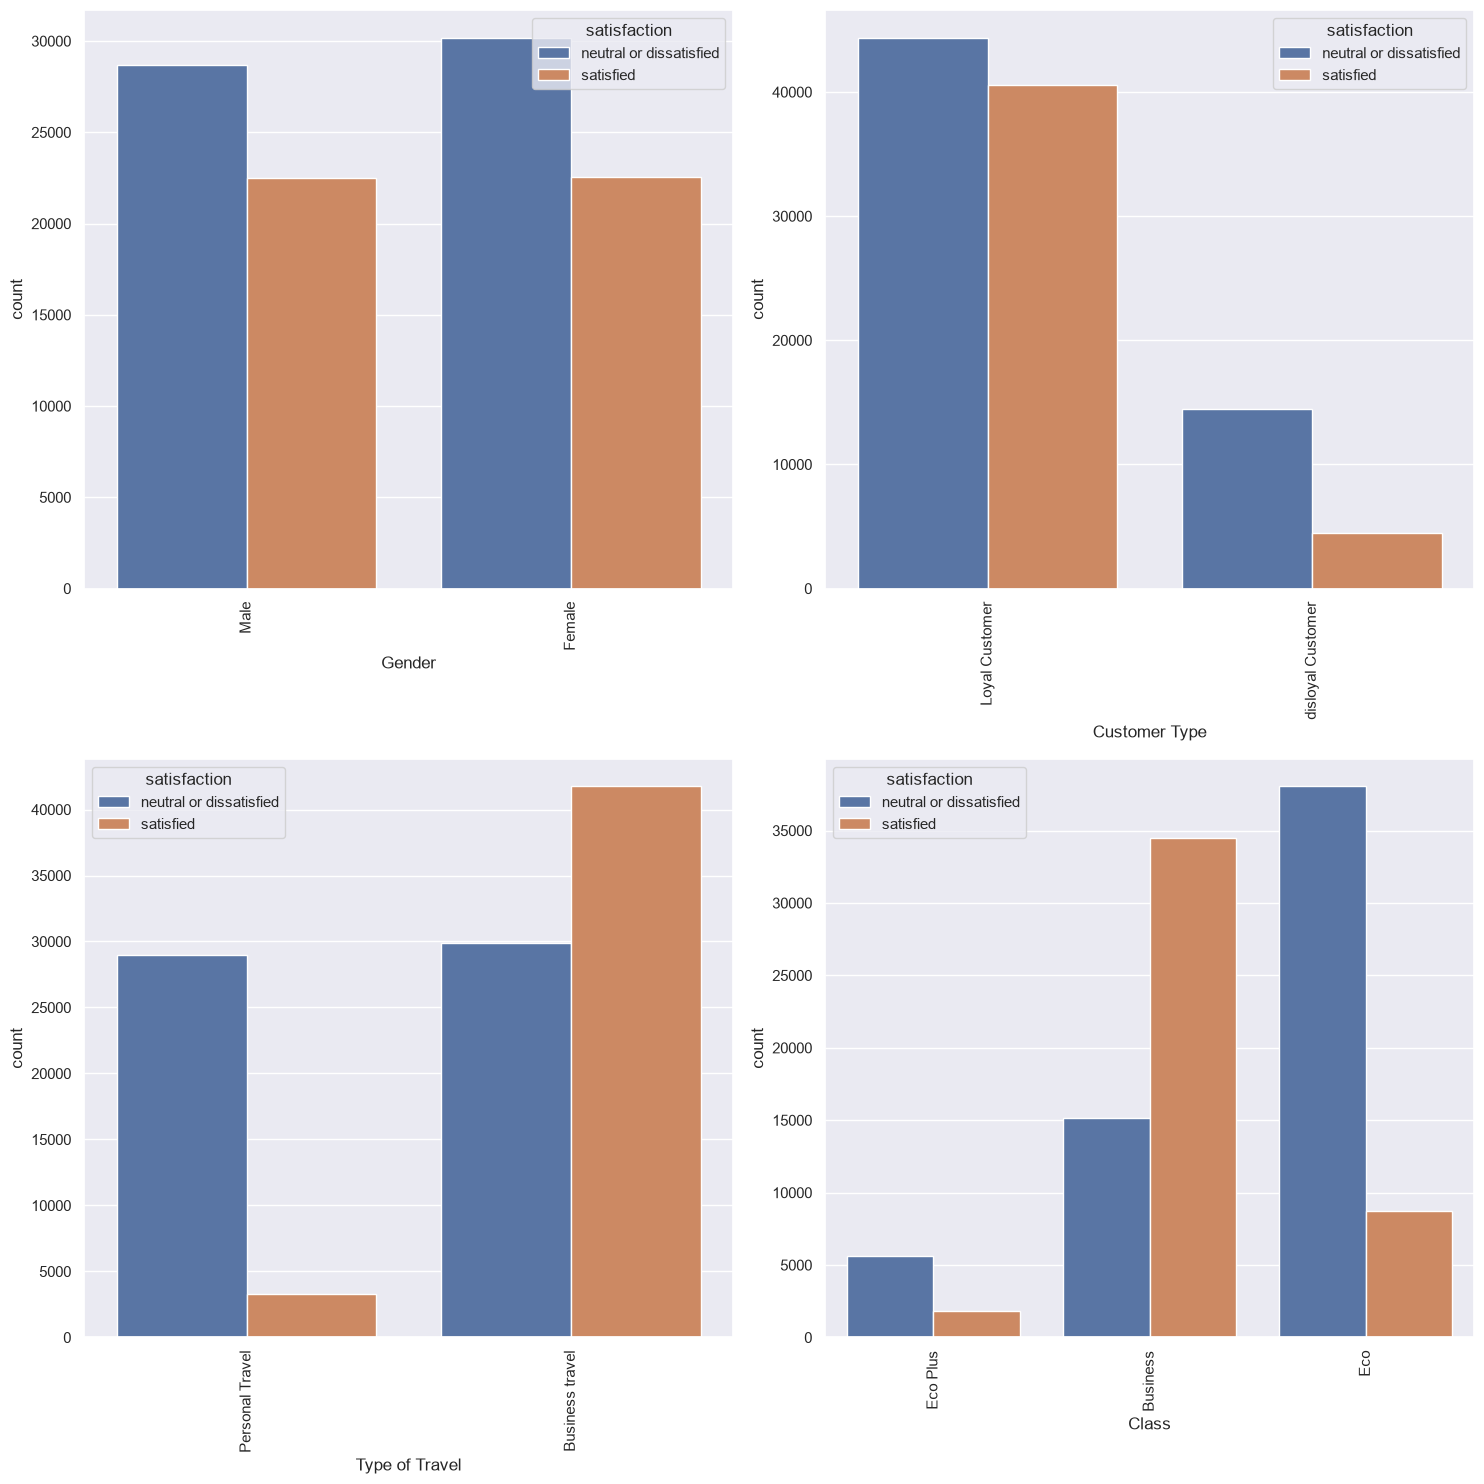

In [4]:
# list of categorical variables to plot
cat_vars = ["Gender", "Customer Type", "Type of Travel", "Class"]

# create figure with subplots
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(15, 15))
axs = axs.flatten()

# create barplot for each categorical variable
for i, var in enumerate(cat_vars):
    sns.countplot(x=var, hue="satisfaction", data=df, ax=axs[i])
    axs[i].set_xticklabels(axs[i].get_xticklabels(), rotation=90)

# adjust spacing between subplots
fig.tight_layout()

# show plot
plt.show()

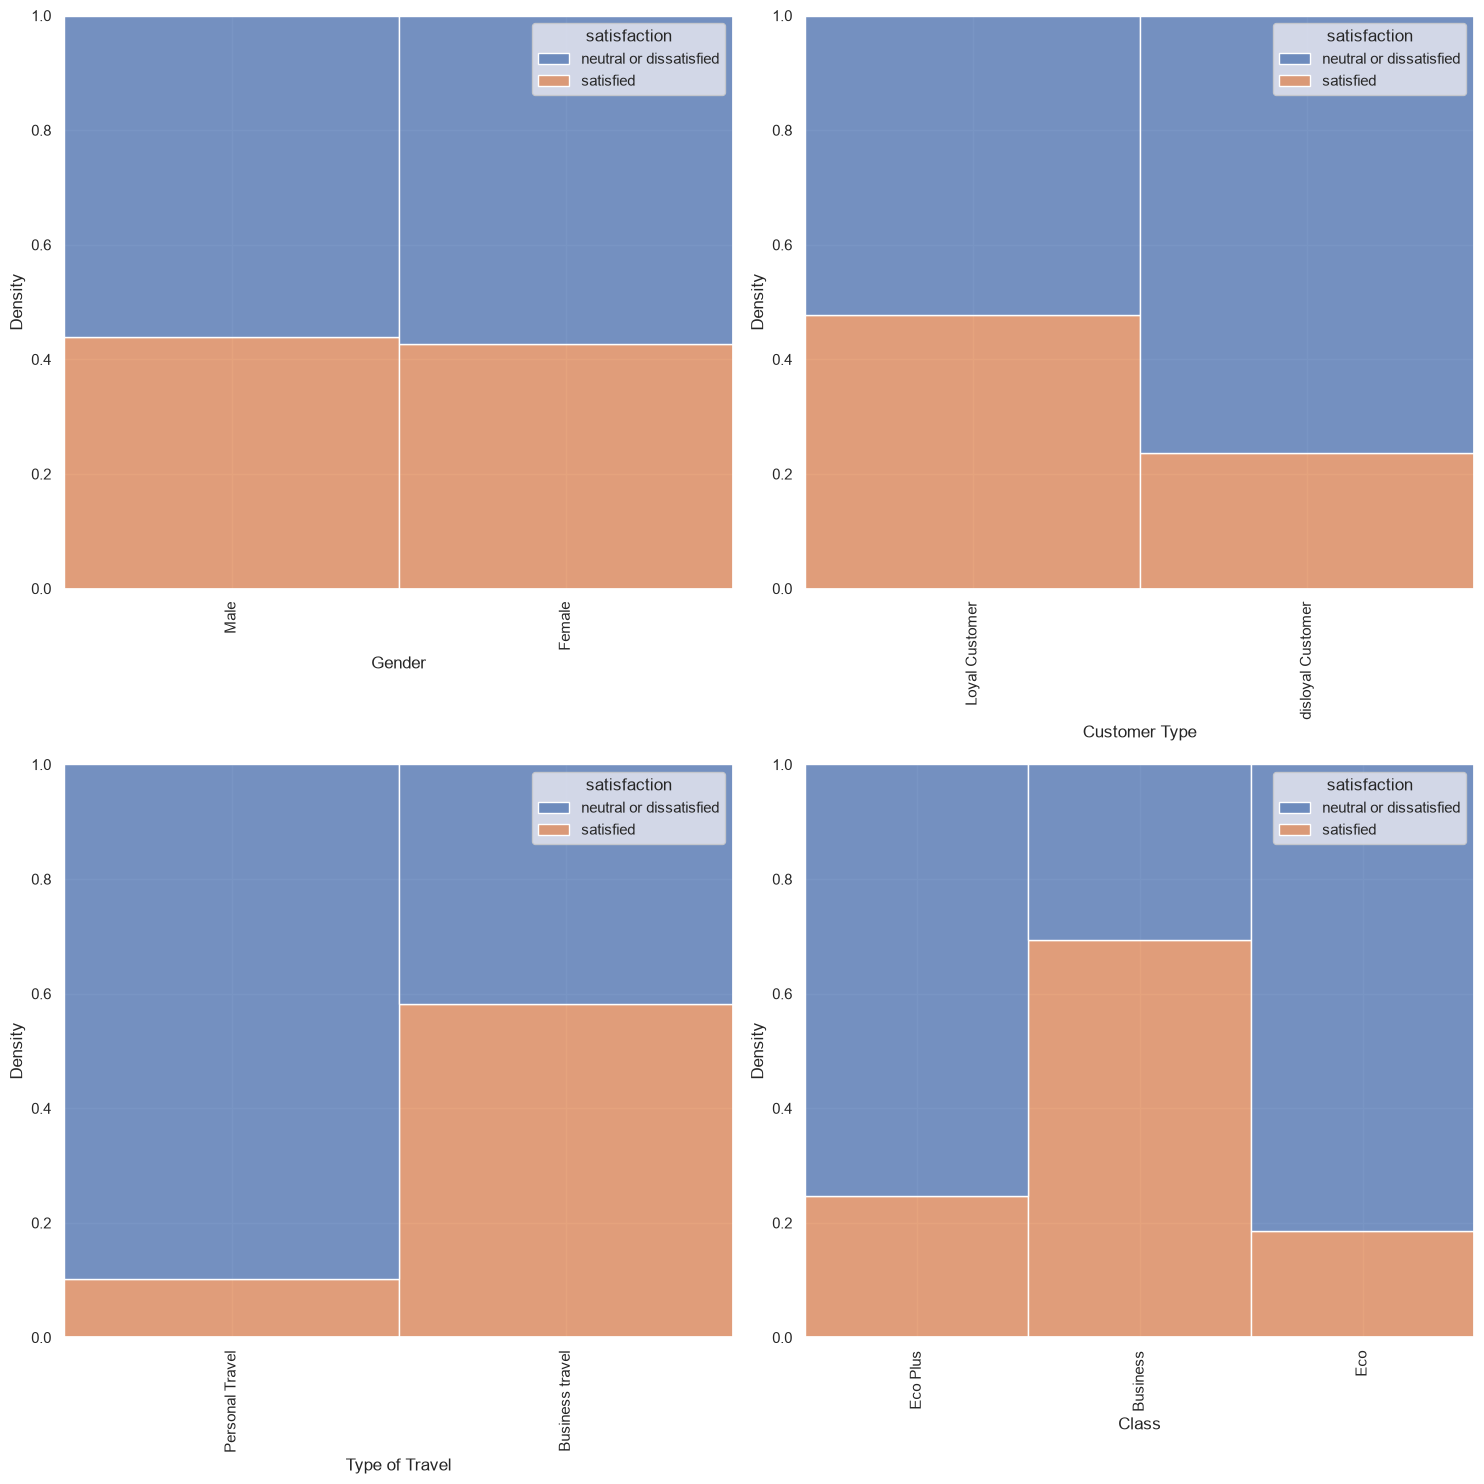

In [5]:
import warnings

warnings.filterwarnings("ignore")
# get list of categorical variables
cat_vars = ["Gender", "Customer Type", "Type of Travel", "Class"]

# create figure with subplots
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(15, 15))
axs = axs.flatten()

# create histplot for each categorical variable
for i, var in enumerate(cat_vars):
    sns.histplot(
        x=var,
        hue="satisfaction",
        data=df,
        ax=axs[i],
        multiple="fill",
        kde=False,
        element="bars",
        fill=True,
        stat="density",
    )
    axs[i].tick_params(
        axis="x", rotation=90
    )  # FIX: labels now come from the plot itself, not df[var].unique()
    axs[i].set_xlabel(var)

# adjust spacing between subplots
fig.tight_layout()

# show plot
plt.show()

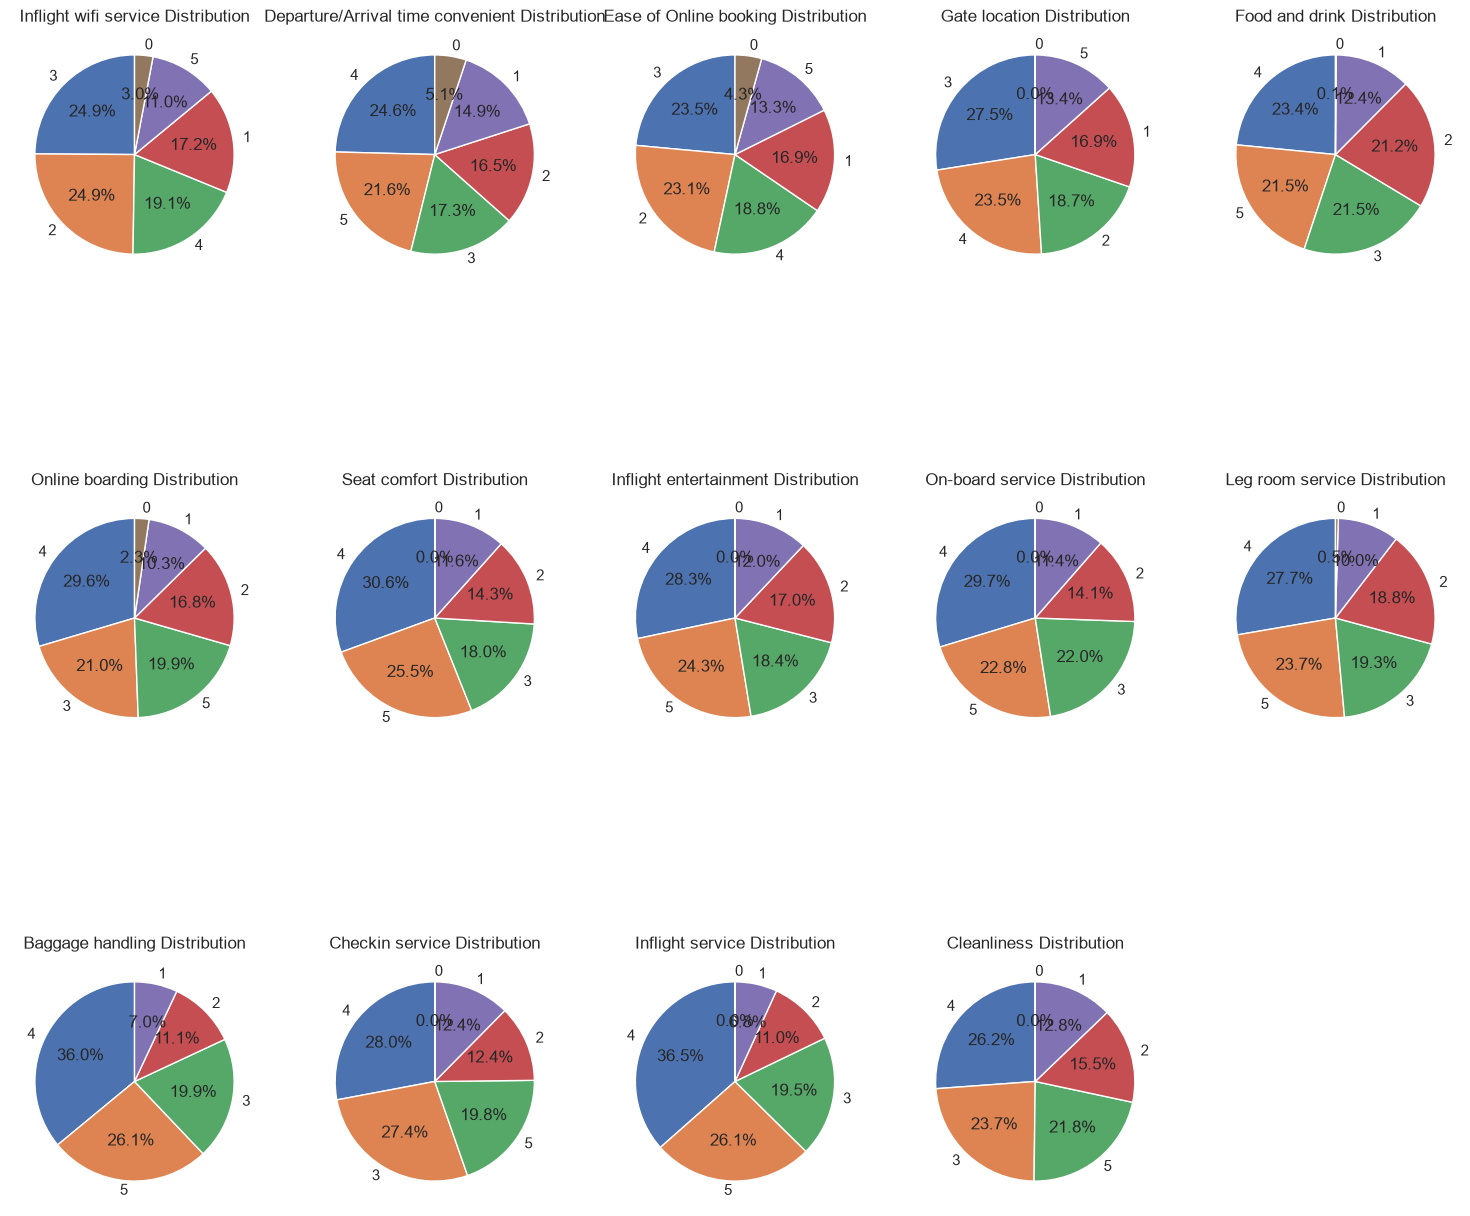

In [6]:
cat_vars = [
    "Inflight wifi service",
    "Departure/Arrival time convenient",
    "Ease of Online booking",
    "Gate location",
    "Food and drink",
    "Online boarding",
    "Seat comfort",
    "Inflight entertainment",
    "On-board service",
    "Leg room service",
    "Baggage handling",
    "Checkin service",
    "Inflight service",
    "Cleanliness",
]

# create a figure and axes
fig, axs = plt.subplots(nrows=3, ncols=5, figsize=(15, 15))

# create a pie chart for each categorical variable
for i, var in enumerate(cat_vars):
    if i < len(axs.flat):
        # count the number of occurrences for each category
        cat_counts = df[var].value_counts()

        # create a pie chart
        axs.flat[i].pie(
            cat_counts, labels=cat_counts.index, autopct="%1.1f%%", startangle=90
        )

        # set a title for each subplot
        axs.flat[i].set_title(f"{var} Distribution")

# adjust spacing between subplots
fig.tight_layout()
fig.delaxes(axs[2][4])
# show the plot
plt.show()

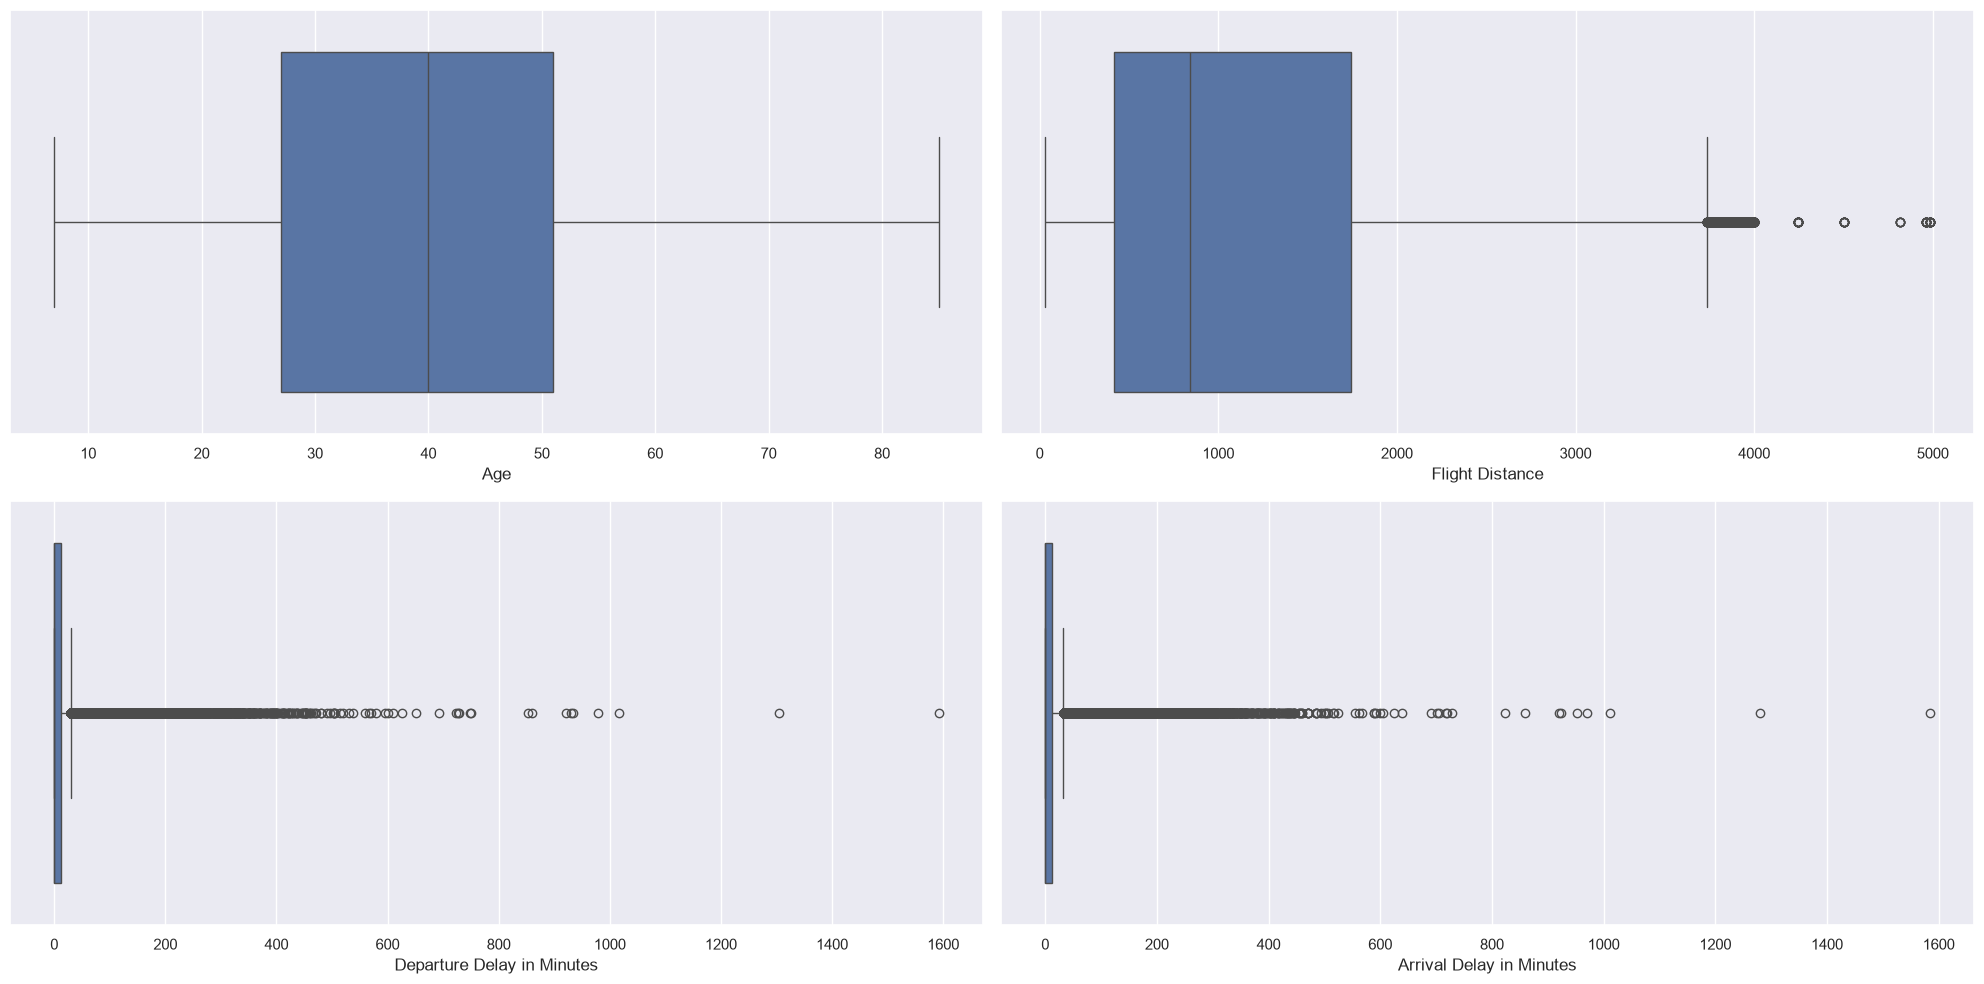

In [7]:
num_vars = [
    "Age",
    "Flight Distance",
    "Departure Delay in Minutes",
    "Arrival Delay in Minutes",
]

fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(20, 10))
axs = axs.flatten()

for i, var in enumerate(num_vars):
    sns.boxplot(x=var, data=df, ax=axs[i])

fig.tight_layout()

plt.show()

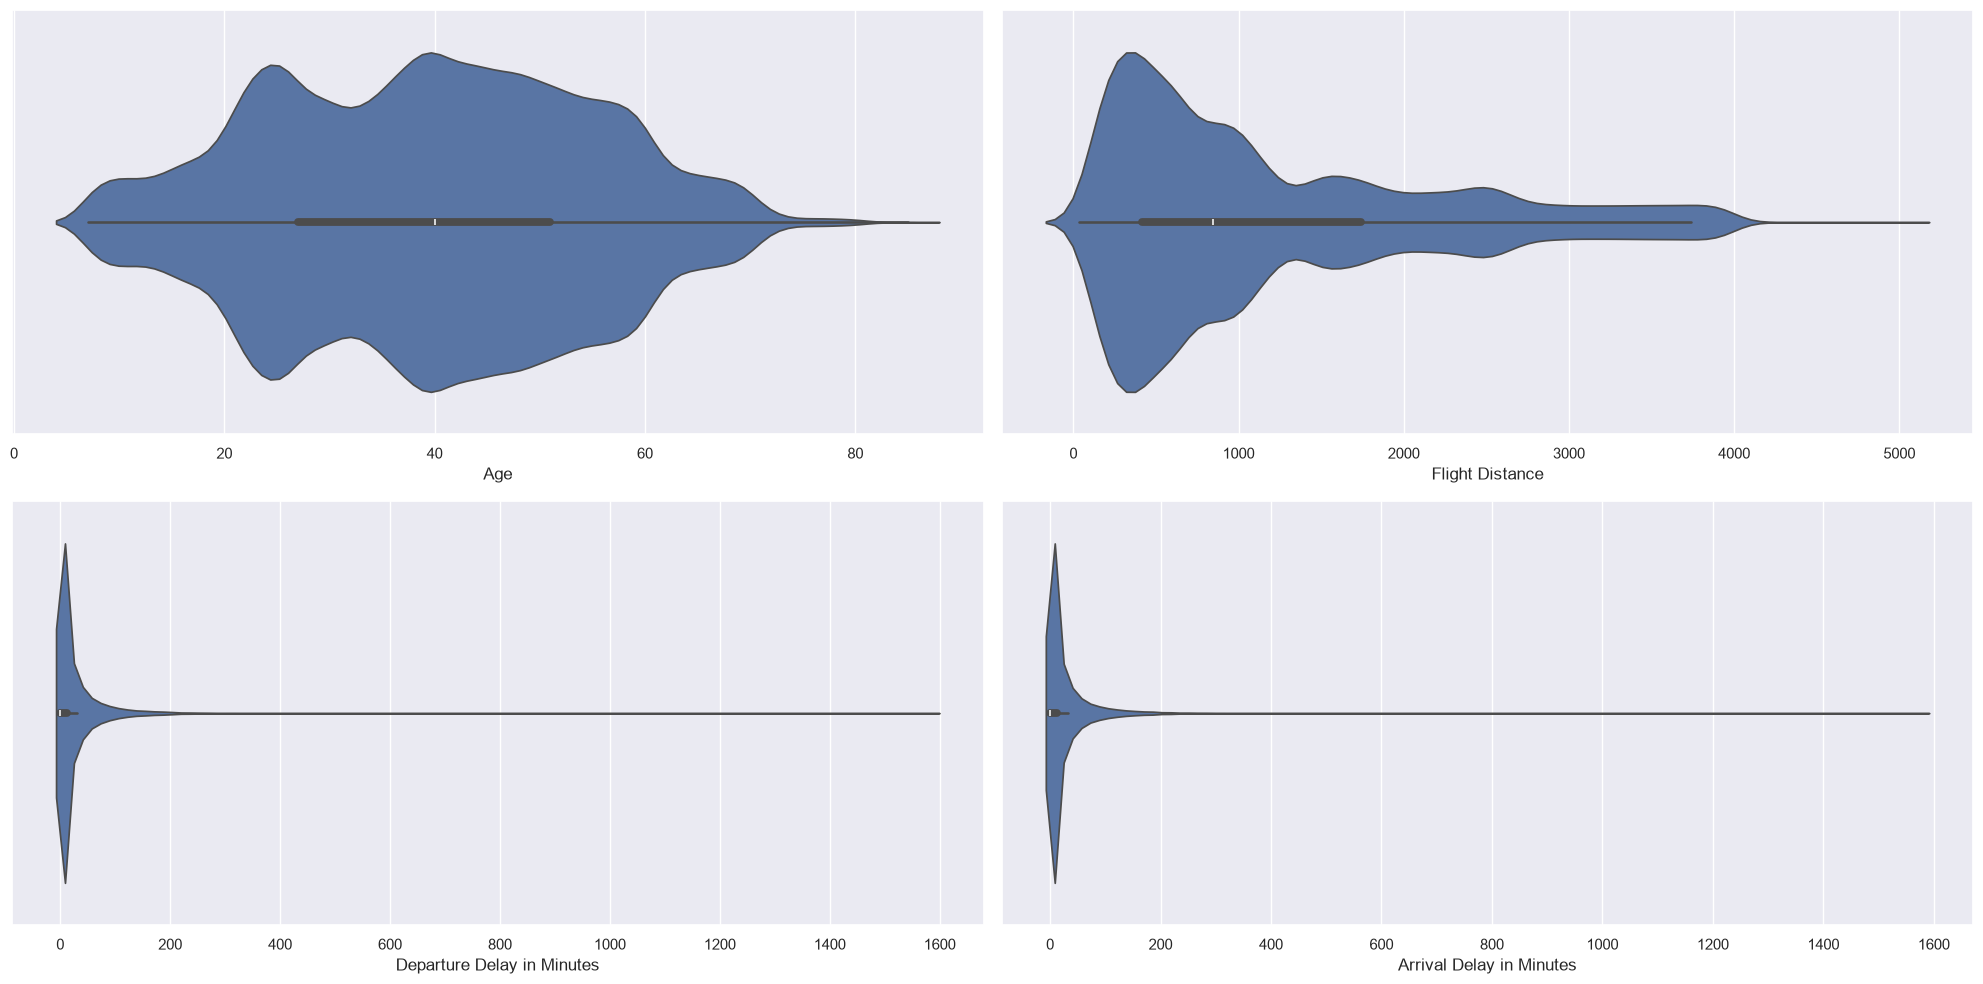

In [8]:
num_vars = [
    "Age",
    "Flight Distance",
    "Departure Delay in Minutes",
    "Arrival Delay in Minutes",
]

fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(20, 10))
axs = axs.flatten()

for i, var in enumerate(num_vars):
    sns.violinplot(x=var, data=df, ax=axs[i])

fig.tight_layout()
plt.show()

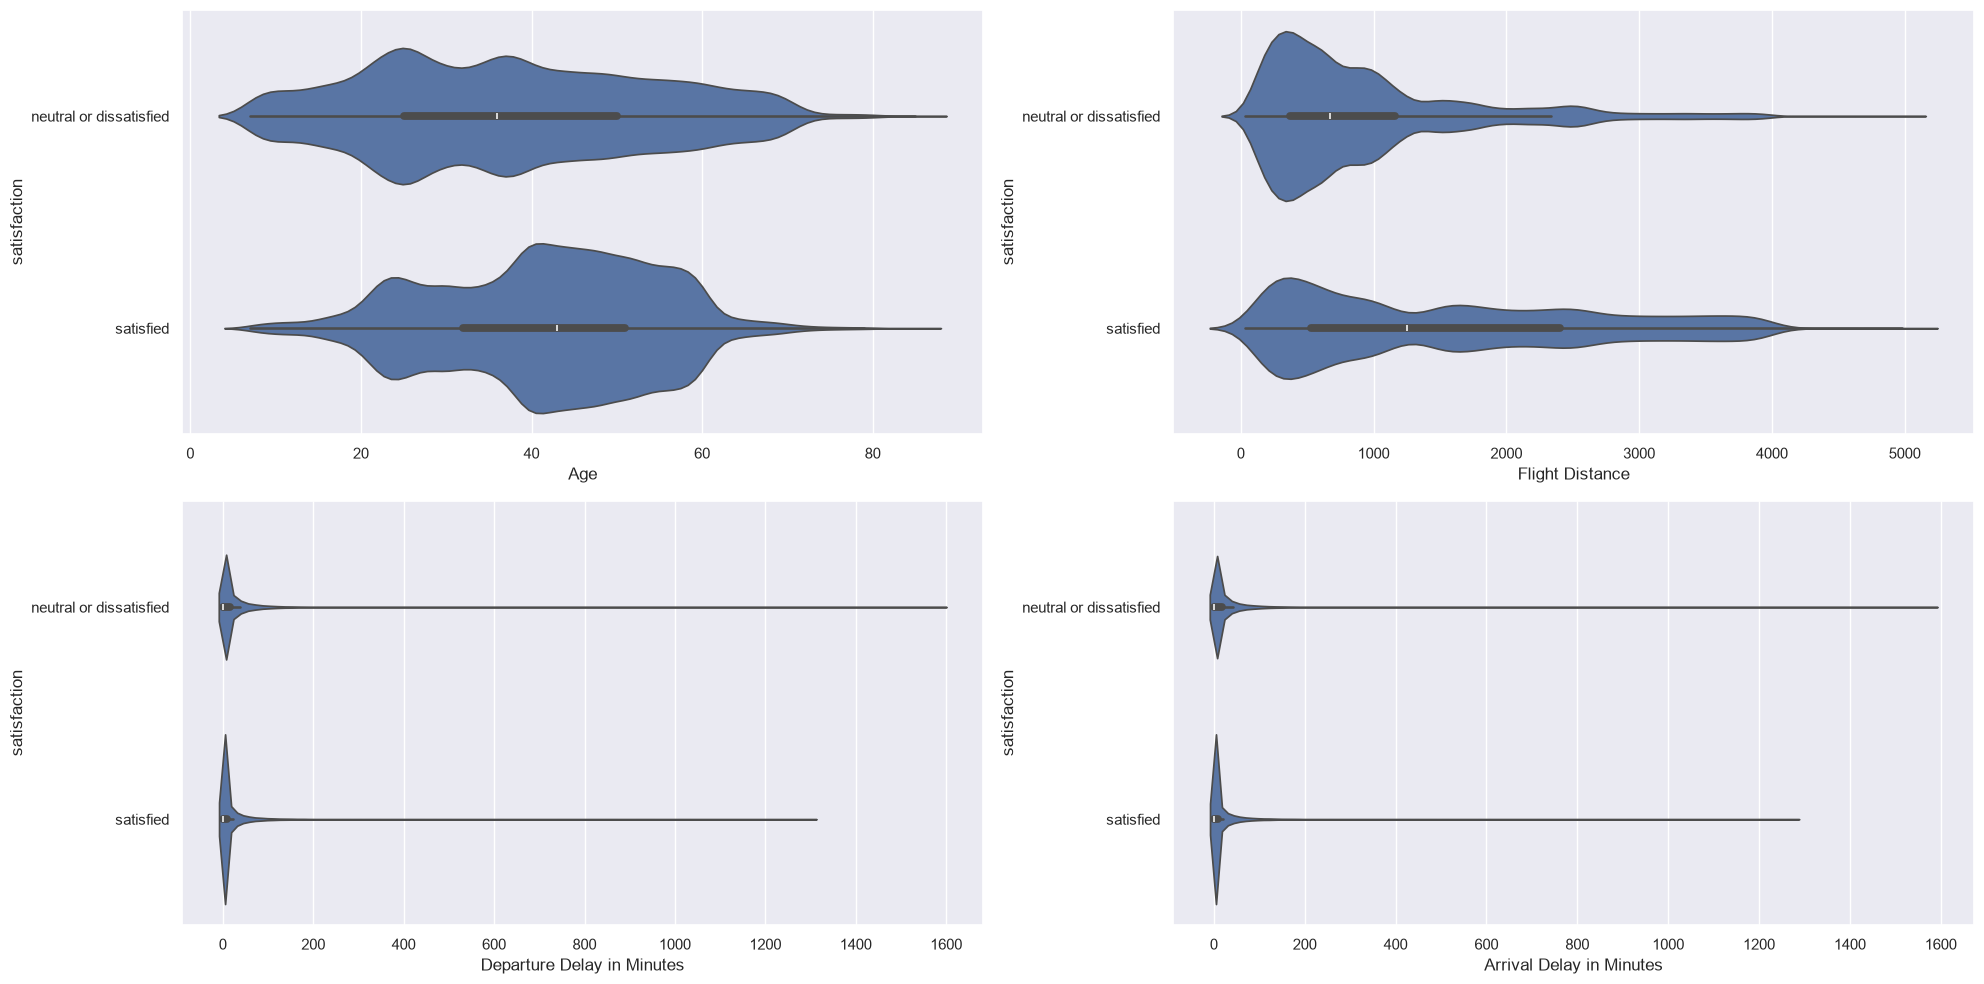

In [9]:
num_vars = [
    "Age",
    "Flight Distance",
    "Departure Delay in Minutes",
    "Arrival Delay in Minutes",
]

fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(20, 10))
axs = axs.flatten()

for i, var in enumerate(num_vars):
    sns.violinplot(x=var, y="satisfaction", data=df, ax=axs[i])

fig.tight_layout()

plt.show()

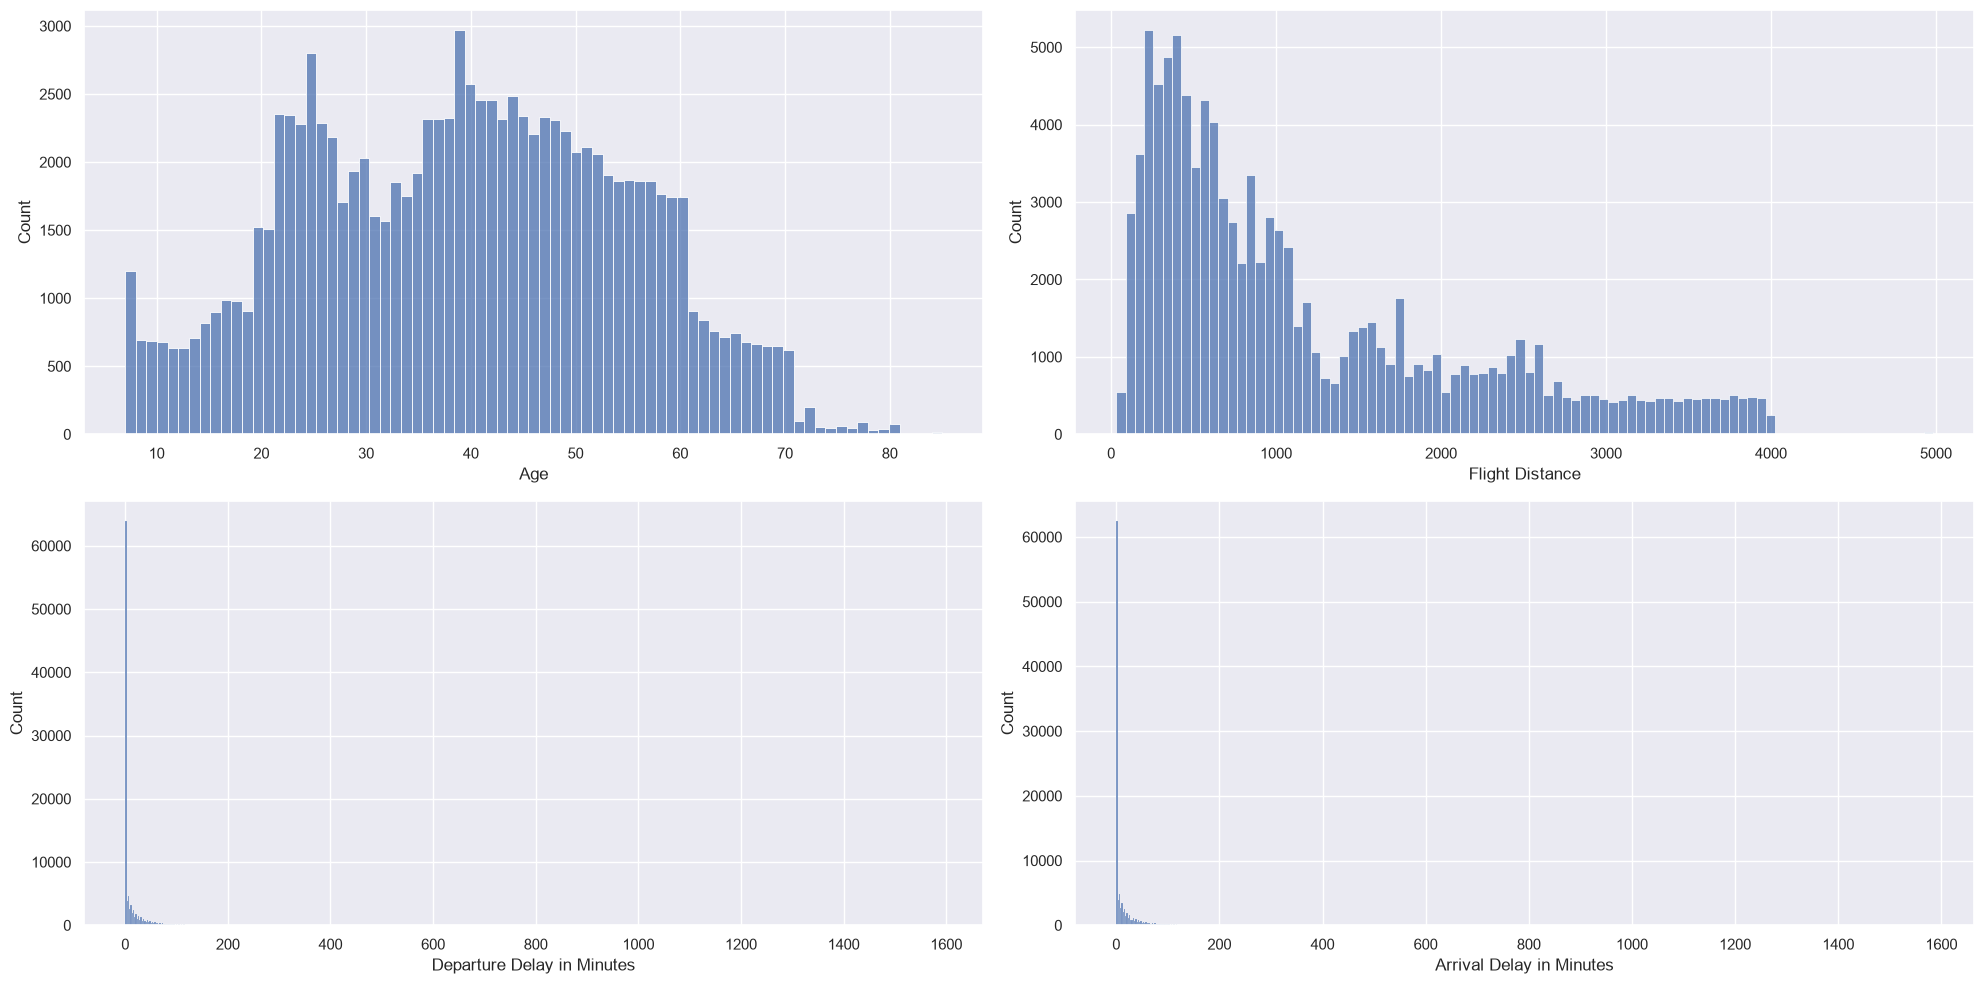

In [10]:
num_vars = [
    "Age",
    "Flight Distance",
    "Departure Delay in Minutes",
    "Arrival Delay in Minutes",
]

fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(20, 10))
axs = axs.flatten()

for i, var in enumerate(num_vars):
    sns.histplot(x=var, data=df, ax=axs[i])

fig.tight_layout()

plt.show()

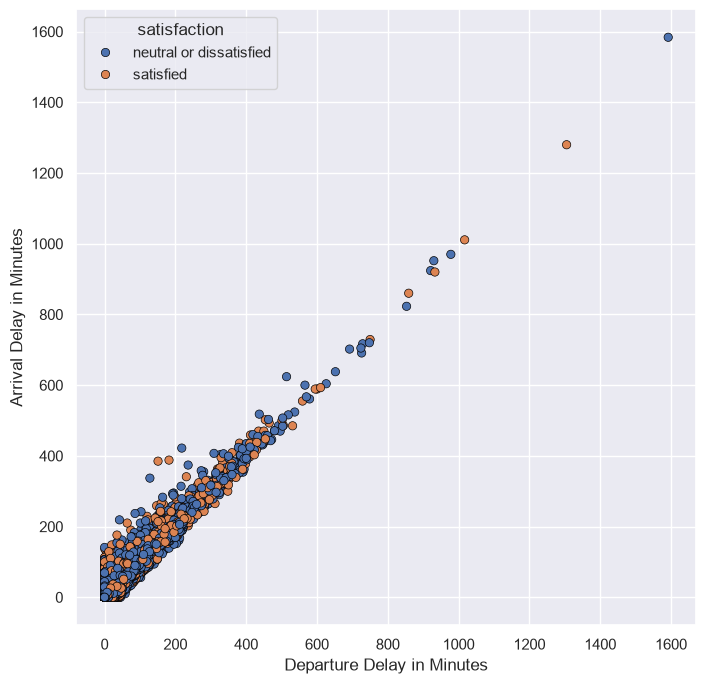

In [11]:
plt.figure(figsize=(8, 8), dpi=100)
sns.scatterplot(
    x="Departure Delay in Minutes",
    y="Arrival Delay in Minutes",
    hue="satisfaction",
    data=df,
    edgecolor="black",
)
plt.show()

# Data Preprocessing

# Check null value

In [12]:
check_missing = df.isnull().sum() * 100 / df.shape[0]
check_missing[check_missing > 0].sort_values(ascending=False)

Arrival Delay in Minutes    0.298352
dtype: float64

In [13]:
df.dtypes

Gender                                   str
Customer Type                            str
Age                                    int64
Type of Travel                           str
Class                                    str
Flight Distance                        int64
Inflight wifi service                  int64
Departure/Arrival time convenient      int64
Ease of Online booking                 int64
Gate location                          int64
Food and drink                         int64
Online boarding                        int64
Seat comfort                           int64
Inflight entertainment                 int64
On-board service                       int64
Leg room service                       int64
Baggage handling                       int64
Checkin service                        int64
Inflight service                       int64
Cleanliness                            int64
Departure Delay in Minutes             int64
Arrival Delay in Minutes             float64
satisfacti

# Show Unique Value each Columns

In [14]:
# Loop over each column in the DataFrame where dtype is 'object'
for col in df.select_dtypes(include=["object"]).columns:
    # Print the column name and the unique values
    print(f"{col}: {df[col].unique()}")

Gender: <ArrowStringArray>
['Male', 'Female']
Length: 2, dtype: str
Customer Type: <ArrowStringArray>
['Loyal Customer', 'disloyal Customer']
Length: 2, dtype: str
Type of Travel: <ArrowStringArray>
['Personal Travel', 'Business travel']
Length: 2, dtype: str
Class: <ArrowStringArray>
['Eco Plus', 'Business', 'Eco']
Length: 3, dtype: str
satisfaction: <ArrowStringArray>
['neutral or dissatisfied', 'satisfied']
Length: 2, dtype: str


# Encoding each categorical column
**Fix:** explicit, fixed mappings (identical for train and test). `Class` is encoded in its natural order Eco < Eco Plus < Business instead of arbitrary alphabetical codes.

In [15]:
maps = {
    "Gender": {"Female": 0, "Male": 1},
    "Customer Type": {"disloyal Customer": 0, "Loyal Customer": 1},
    "Type of Travel": {"Personal Travel": 0, "Business travel": 1},
    "Class": {"Eco": 0, "Eco Plus": 1, "Business": 2},
    "satisfaction": {"neutral or dissatisfied": 0, "satisfied": 1},
}
for col, m in maps.items():
    df[col] = df[col].map(m)
    df_test[col] = df_test[col].map(m)
    assert df[col].notna().all() and df_test[col].notna().all(), col
    print(f"{col}: {sorted(df[col].unique().tolist())}")

Gender: [0, 1]
Customer Type: [0, 1]
Type of Travel: [0, 1]
Class: [0, 1, 2]
satisfaction: [0, 1]


# Check class value

satisfaction
0    58879
1    45025
Name: count, dtype: int64
satisfaction
0    0.567
1    0.433
Name: proportion, dtype: float64


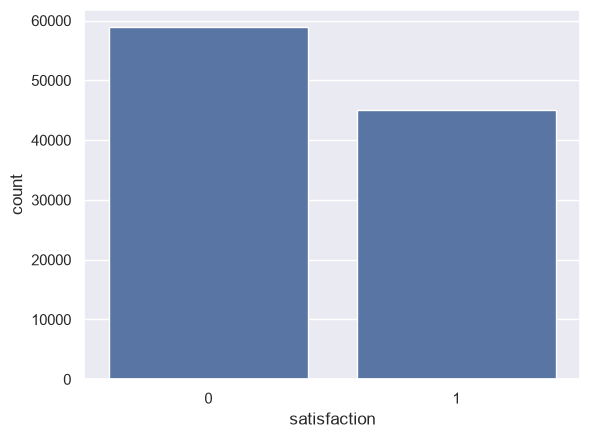

In [16]:
sns.countplot(
    x="satisfaction", data=df
)  # FIX: explicit x= (positional use breaks in newer seaborn)
print(df["satisfaction"].value_counts())
print(df["satisfaction"].value_counts(normalize=True).round(3))

In [17]:
column_names = [
    "Age",
    "Flight Distance",
    "Departure Delay in Minutes",
    "Arrival Delay in Minutes",
]
rows = []
for column_name in column_names:
    Q1, Q3 = df[column_name].quantile(0.25), df[column_name].quantile(0.75)
    IQR = Q3 - Q1
    low, high = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    flagged = (df[column_name] < low) | (df[column_name] > high)
    rows.append(
        {
            "column": column_name,
            "lower fence": low,
            "upper fence": high,
            "rows flagged": int(flagged.sum()),
            "% flagged": round(100 * flagged.mean(), 1),
            "satisfied rate (flagged)": round(df.loc[flagged, "satisfaction"].mean(), 3)
            if flagged.any()
            else None,
        }
    )
print("overall satisfied rate:", round(df["satisfaction"].mean(), 3))
pd.DataFrame(rows)

overall satisfied rate: 0.433


,column,lower fence,upper fence,rows flagged,% flagged,satisfied rate (flagged)
0,Age,-9.0,87.0,0,0.0,NaN
1,Flight Distance,-1579.5,3736.5,2291,2.2,0.767
2,Departure Delay in Minutes,-18.0,30.0,14529,14.0,0.361
3,Arrival Delay in Minutes,-19.5,32.5,13954,13.4,0.357


<Axes: >

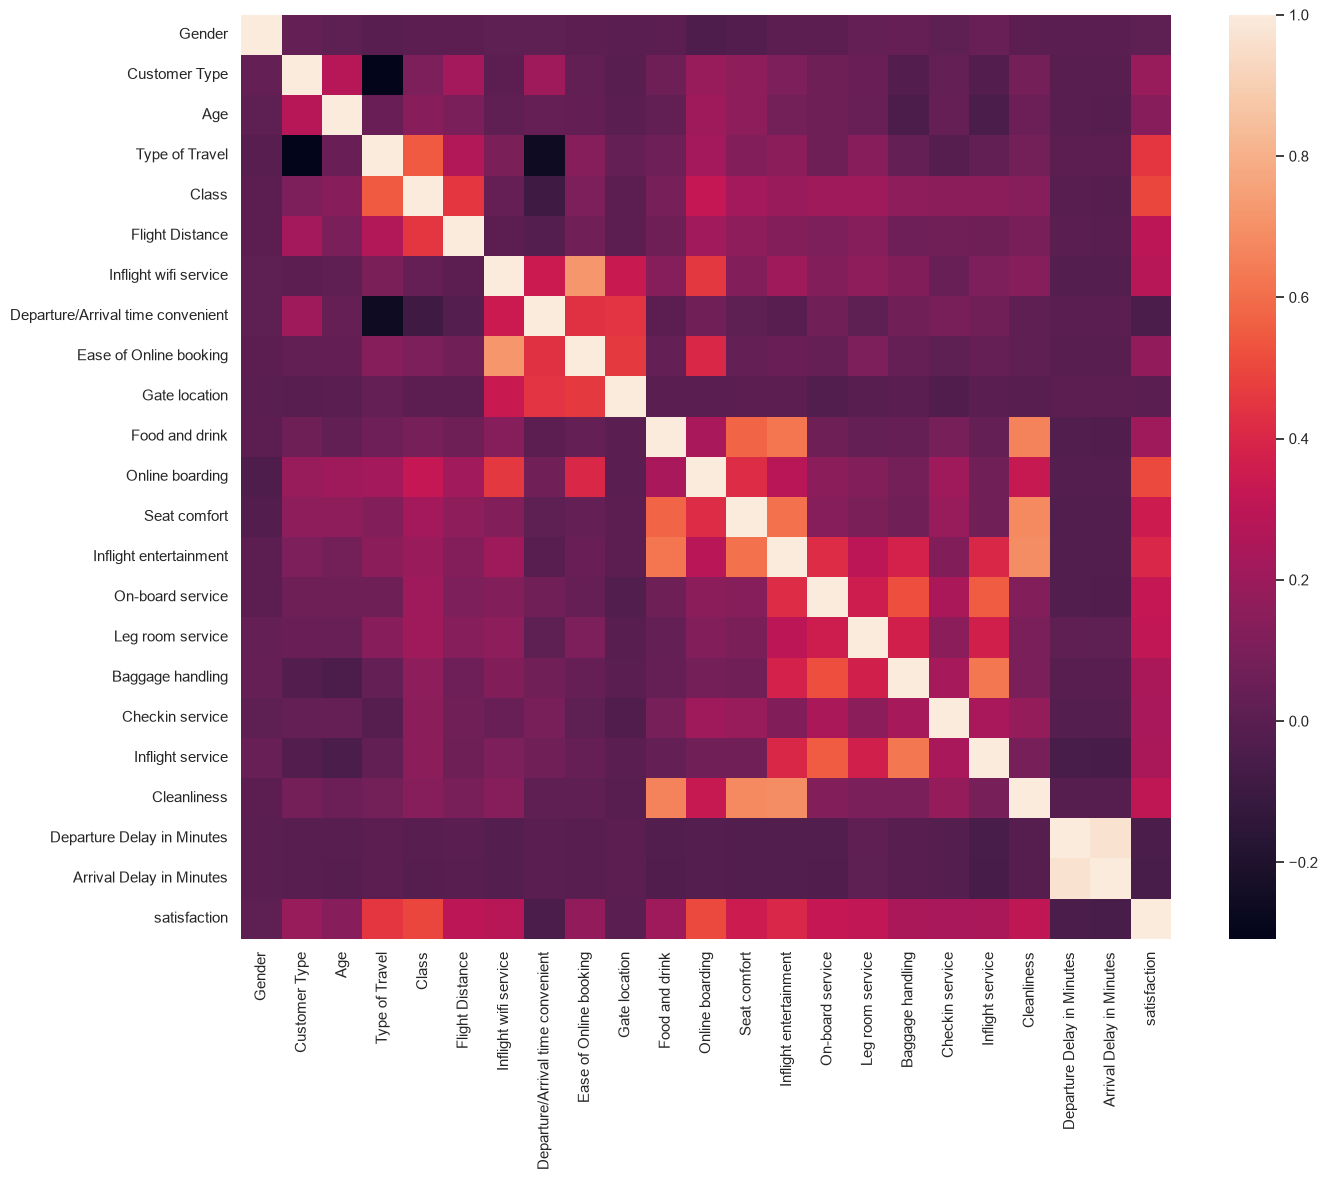

In [18]:
plt.figure(figsize=(15, 12))
sns.heatmap(df.corr(), fmt=".2g")

# Machine Learning Model Building

In [19]:
X = df.drop("satisfaction", axis=1)
y = df["satisfaction"]

In [20]:
# validation size 20% and train size 80% (stratified, split BEFORE any fitting step)
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=0, stratify=y
)

# official held-out test set (not used until the final evaluation)
X_test = df_test.drop("satisfaction", axis=1).copy()
y_test = df_test["satisfaction"]
print(X_train.shape, X_valid.shape, X_test.shape)

(83123, 22) (20781, 22) (25976, 22)


In [21]:
# Median imputation fitted on the TRAINING split only, then applied to validation and test
X_train, X_valid = X_train.copy(), X_valid.copy()
median_delay = X_train["Arrival Delay in Minutes"].median()
for part in (X_train, X_valid, X_test):
    part["Arrival Delay in Minutes"] = part["Arrival Delay in Minutes"].fillna(
        median_delay
    )
print(
    "train median used:",
    median_delay,
    "| remaining NaN:",
    int(
        X_train.isna().sum().sum()
        + X_valid.isna().sum().sum()
        + X_test.isna().sum().sum()
    ),
)

train median used: 0.0 | remaining NaN: 0


# Decision Tree

In [22]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

dtree = DecisionTreeClassifier(class_weight="balanced", random_state=0)
param_grid = {
    "max_depth": [3, 4, 5, 6, 7, 8],
    "min_samples_split": [2, 3, 4],
    "min_samples_leaf": [1, 2, 3, 4],
}

# Perform a grid search with (stratified) 5-fold cross-validation on the TRAINING split only
grid_search = GridSearchCV(dtree, param_grid, cv=5, n_jobs=-1)
grid_search.fit(X_train, y_train)

# Print the best hyperparameters
print(grid_search.best_params_)
print("best CV accuracy: %.4f" % grid_search.best_score_)

{'max_depth': 8, 'min_samples_leaf': 4, 'min_samples_split': 2}
best CV accuracy: 0.9377


In [23]:
from sklearn.tree import DecisionTreeClassifier

dtree = DecisionTreeClassifier(
    random_state=0, class_weight="balanced", **grid_search.best_params_
)  # best params taken from the search, not typed in by hand
dtree.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",8
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are cons

In [24]:
y_pred = dtree.predict(X_valid)
print(
    "Validation Accuracy Score :", round(accuracy_score(y_valid, y_pred) * 100, 2), "%"
)

Validation Accuracy Score : 93.51 %


In [25]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    jaccard_score,
    log_loss,
    roc_auc_score,
)

# FIX: binary averaging (micro-averaging made F1, precision and recall all equal to accuracy) and log loss on probabilities, not hard labels
print("F-1 Score : ", (f1_score(y_valid, y_pred)))
print("Precision Score : ", (precision_score(y_valid, y_pred)))
print("Recall Score : ", (recall_score(y_valid, y_pred)))
print("Jaccard Score : ", (jaccard_score(y_valid, y_pred)))
print("Log Loss : ", (log_loss(y_valid, dtree.predict_proba(X_valid))))
print("ROC-AUC : ", (roc_auc_score(y_valid, dtree.predict_proba(X_valid)[:, 1])))

F-1 Score :  0.9253582692414098
Precision Score :  0.9221438023820027
Recall Score :  0.9285952248750694
Jaccard Score :  0.8610853671094635
Log Loss :  0.16582764976409034
ROC-AUC :  0.984367569043768


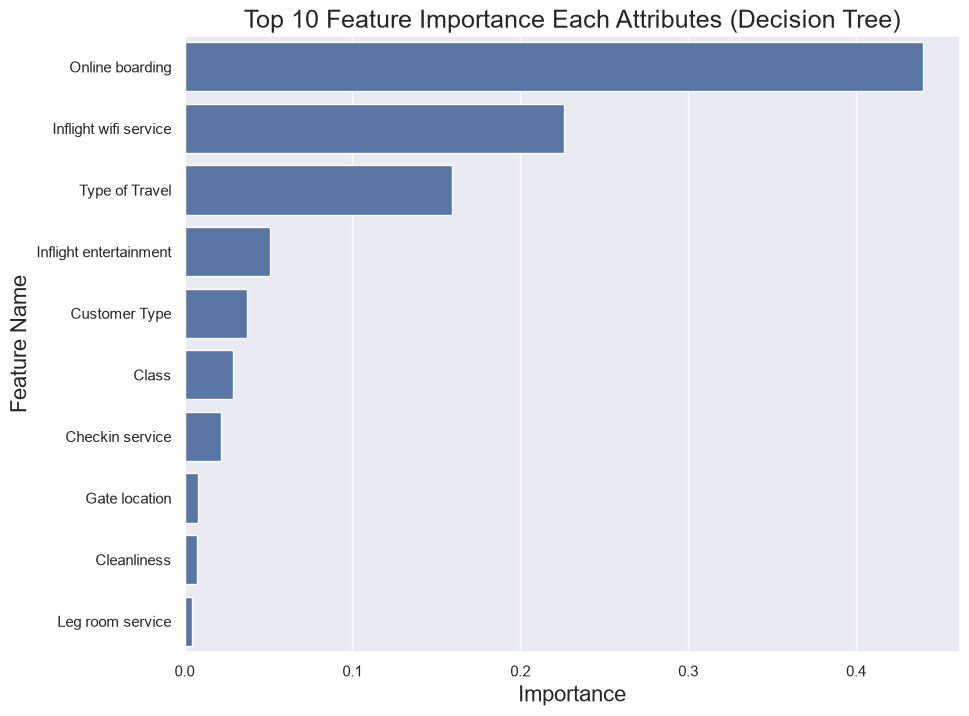

In [26]:
imp_df = pd.DataFrame(
    {"Feature Name": X_train.columns, "Importance": dtree.feature_importances_}
)
fi = imp_df.sort_values(by="Importance", ascending=False)

fi2 = fi.head(10)
plt.figure(figsize=(10, 8))
sns.barplot(data=fi2, x="Importance", y="Feature Name")
plt.title("Top 10 Feature Importance Each Attributes (Decision Tree)", fontsize=18)
plt.xlabel("Importance", fontsize=16)
plt.ylabel("Feature Name", fontsize=16)
plt.show()

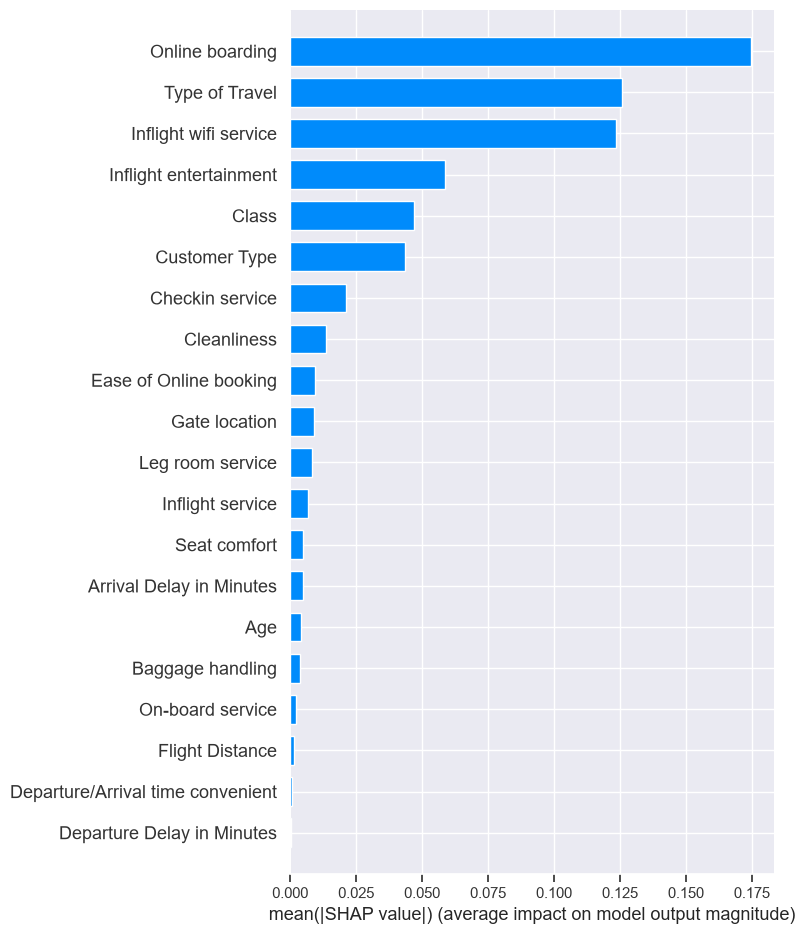

In [29]:
import shap

sample = X_valid.sample(2000, random_state=0)  # a sample keeps SHAP fast
explainer = shap.TreeExplainer(dtree)
shap_values = explainer.shap_values(sample)
# older shap returns a list [class0, class1]; newer returns an array (rows, features, classes)
sv = (
    shap_values[1]
    if isinstance(shap_values, list)
    else (shap_values[..., 1] if getattr(shap_values, "ndim", 2) == 3 else shap_values)
)
shap.summary_plot(sv, sample, plot_type="bar")

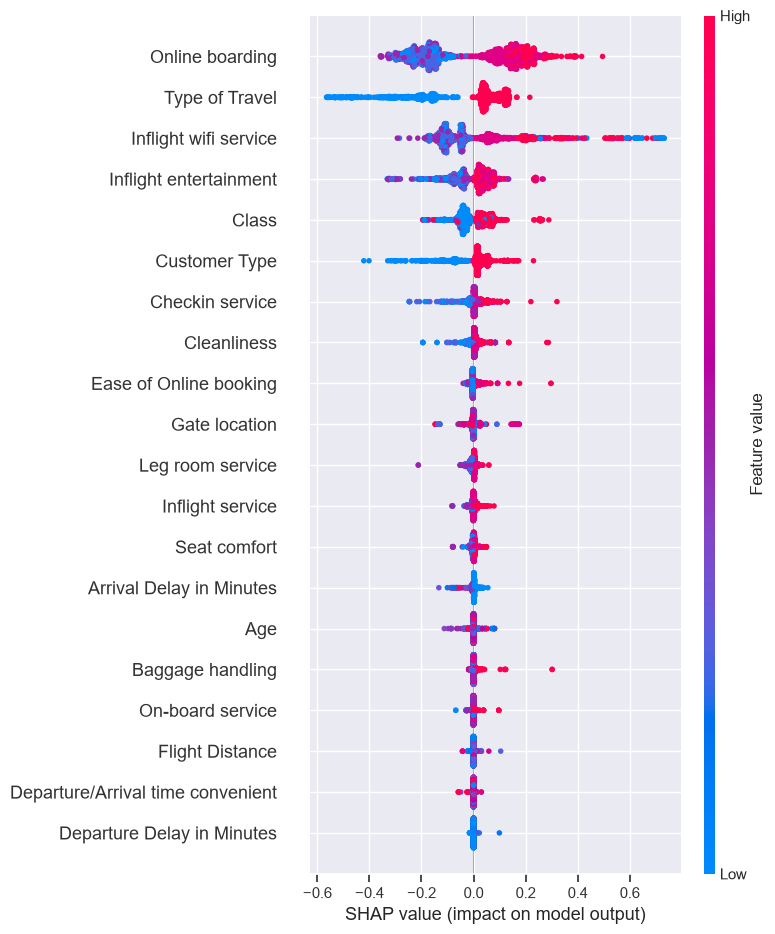

In [30]:
# SHAP values for the 'satisfied' class
shap.summary_plot(sv, sample.values, feature_names=sample.columns)

Text(0.5, 1.0, 'Validation accuracy, Decision Tree: 0.9351')

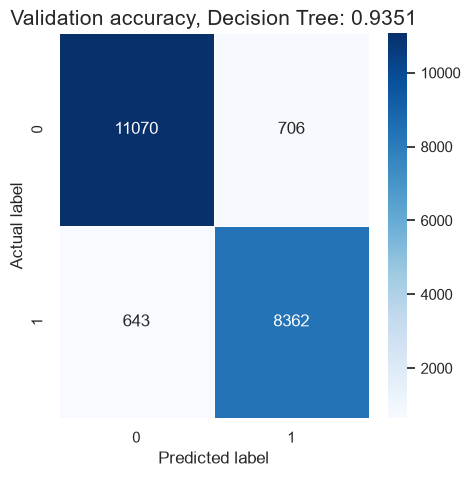

In [31]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_valid, y_pred)
plt.figure(figsize=(5, 5))
sns.heatmap(data=cm, linewidths=0.5, annot=True, fmt="d", cmap="Blues")
plt.ylabel("Actual label")
plt.xlabel("Predicted label")
all_sample_title = "Validation accuracy, Decision Tree: {0:.4f}".format(
    dtree.score(X_valid, y_valid)
)
plt.title(all_sample_title, size=15)

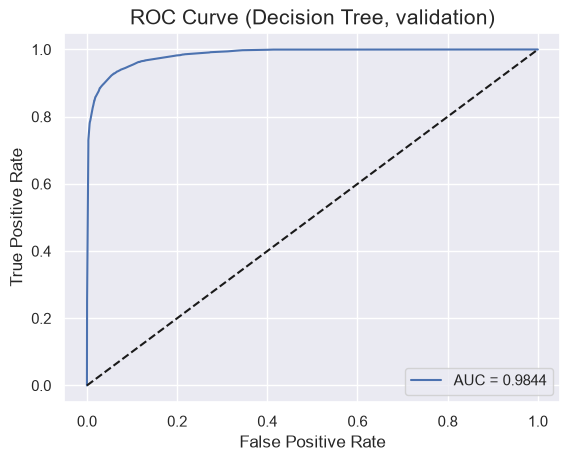

In [32]:
from sklearn.metrics import roc_curve, roc_auc_score

y_pred_proba = dtree.predict_proba(X_valid)[:][:, 1]

df_actual_predicted = pd.concat(
    [
        pd.DataFrame(np.array(y_valid), columns=["y_actual"]),
        pd.DataFrame(y_pred_proba, columns=["y_pred_proba"]),
    ],
    axis=1,
)
df_actual_predicted.index = y_valid.index

fpr, tpr, tr = roc_curve(
    df_actual_predicted["y_actual"], df_actual_predicted["y_pred_proba"]
)
auc = roc_auc_score(
    df_actual_predicted["y_actual"], df_actual_predicted["y_pred_proba"]
)

plt.plot(fpr, tpr, label="AUC = %0.4f" % auc)
plt.plot(fpr, fpr, linestyle="--", color="k")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve (Decision Tree, validation)", size=15)
plt.legend()

# Random Forest 

In [33]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

rfc = RandomForestClassifier(class_weight="balanced", random_state=0)
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10],
    "max_features": [
        "sqrt",
        "log2",
    ],  # max_features=None (all features) dropped: 5-10x slower per fit and never the best option
}

# Perform a grid search with (stratified) 5-fold cross-validation on the TRAINING split only
grid_search = GridSearchCV(rfc, param_grid, cv=5, n_jobs=-1)
grid_search.fit(X_train, y_train)

# Print the best hyperparameters
print(grid_search.best_params_)
print("best CV accuracy: %.4f" % grid_search.best_score_)

{'max_depth': None, 'max_features': 'sqrt', 'n_estimators': 200}
best CV accuracy: 0.9616


In [34]:
from sklearn.ensemble import RandomForestClassifier

rfc = RandomForestClassifier(
    random_state=0, class_weight="balanced", n_jobs=-1, **grid_search.best_params_
)
rfc.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",0
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fea

In [35]:
y_pred = rfc.predict(X_valid)
print(
    "Validation Accuracy Score :", round(accuracy_score(y_valid, y_pred) * 100, 2), "%"
)

Validation Accuracy Score : 96.13 %


In [36]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    jaccard_score,
    log_loss,
    roc_auc_score,
)

print("F-1 Score : ", (f1_score(y_valid, y_pred)))
print("Precision Score : ", (precision_score(y_valid, y_pred)))
print("Recall Score : ", (recall_score(y_valid, y_pred)))
print("Jaccard Score : ", (jaccard_score(y_valid, y_pred)))
print("Log Loss : ", (log_loss(y_valid, rfc.predict_proba(X_valid))))
print("ROC-AUC : ", (roc_auc_score(y_valid, rfc.predict_proba(X_valid)[:, 1])))

F-1 Score :  0.9548872180451128
Precision Score :  0.9650674832709538
Recall Score :  0.9449194891726819
Jaccard Score :  0.9136690647482014
Log Loss :  0.10579261419000219
ROC-AUC :  0.9938159261611907


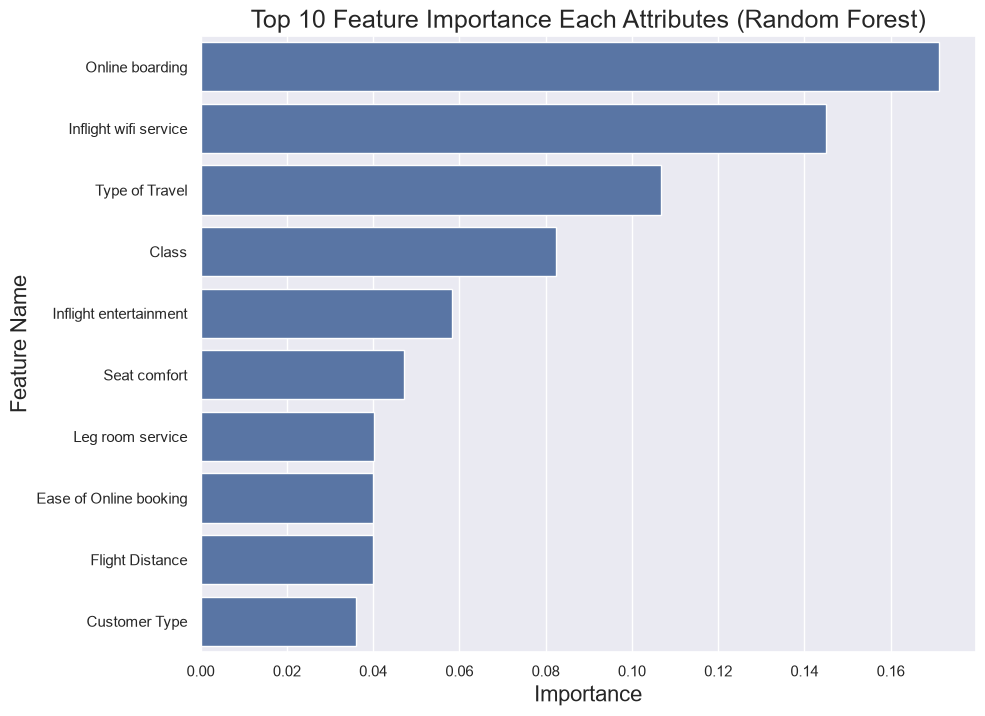

In [37]:
imp_df = pd.DataFrame(
    {"Feature Name": X_train.columns, "Importance": rfc.feature_importances_}
)
fi = imp_df.sort_values(by="Importance", ascending=False)

fi2 = fi.head(10)
plt.figure(figsize=(10, 8))
sns.barplot(data=fi2, x="Importance", y="Feature Name")
plt.title("Top 10 Feature Importance Each Attributes (Random Forest)", fontsize=18)
plt.xlabel("Importance", fontsize=16)
plt.ylabel("Feature Name", fontsize=16)
plt.show()

# Model comparison on the validation set (with a baseline)

In [38]:
from sklearn.dummy import DummyClassifier

base = DummyClassifier(strategy="prior").fit(X_train, y_train)
models = {"Majority baseline": base, "Decision Tree": dtree, "Random Forest": rfc}
rows = []
for name, m in models.items():
    p = m.predict(X_valid)
    pp = m.predict_proba(X_valid)[:, 1]
    rows.append(
        {
            "model": name,
            "accuracy": accuracy_score(y_valid, p),
            "F1": f1_score(y_valid, p),
            "ROC-AUC": roc_auc_score(y_valid, pp),
        }
    )
comparison = pd.DataFrame(rows).set_index("model").round(4)
comparison

,accuracy,F1,ROC-AUC
model,,,
Majority baseline,0.5667,0.0000,0.5000
Decision Tree,0.9351,0.9254,0.9844
Random Forest,0.9613,0.9549,0.9938


# Final evaluation on the official `test.csv` (used once)
Random Forest is selected from the validation table above; the held-out test set is scored only now.

Test Accuracy : 96.14 %
Test F1       : 0.9556
Test ROC-AUC  : 0.9939
Majority-baseline test accuracy: 56.1 %


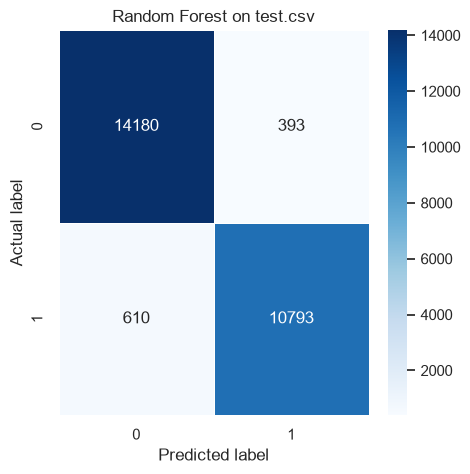

In [39]:
final_model = rfc
y_test_pred = final_model.predict(X_test)
y_test_proba = final_model.predict_proba(X_test)[:, 1]
print("Test Accuracy :", round(accuracy_score(y_test, y_test_pred) * 100, 2), "%")
print("Test F1       :", round(f1_score(y_test, y_test_pred), 4))
print("Test ROC-AUC  :", round(roc_auc_score(y_test, y_test_proba), 4))
print(
    "Majority-baseline test accuracy:",
    round(accuracy_score(y_test, base.predict(X_test)) * 100, 2),
    "%",
)
plt.figure(figsize=(5, 5))
sns.heatmap(
    confusion_matrix(y_test, y_test_pred),
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5,
)
plt.ylabel("Actual label")
plt.xlabel("Predicted label")
plt.title("Random Forest on test.csv")
plt.show()